In [25]:
pip install roboflow

In [26]:
pip install -U ultralytics

## connecting to roboflow

In [34]:

from roboflow import Roboflow

rf = Roboflow(api_key="3qF7uOmgnmuMPU6A7J8t")
project = rf.workspace("hassans-workspace-sc7zh").project("damage-detection-v4wmg")
version = project.version(5)

dataset = version.download("yolo11")
print(dataset.location)




loading Roboflow workspace...
loading Roboflow project...
Exporting format yolo11 in progress : 95.0%
Version export complete for yolo11 format



Extracting Dataset Version Zip to damage-detection-5 in yolo11:: 100%|██████████| 1110/1110 [00:00<00:00, 3720.07it/s]


/content/damage-detection-5


## Building and training the model

In [36]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

results = model.train(
    data=f"/content/damage-detection-5/data.yaml",
    imgsz=500,
    epochs=40,
    patience=5
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/damage-detection-5/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=500, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=None, opset=None, optimize=Fal

In [39]:
model = YOLO(r"/content/runs/detect/train-3/weights/best.pt")
results = model.predict(r"/content/00029.jpg", save=True)
print(model.names)


image 1/1 /content/00029.jpg: 512x512 1 Hole, 11.3ms
Speed: 29.1ms preprocess, 11.3ms inference, 14.8ms postprocess per image at shape (1, 3, 512, 512)
Results saved to /content/runs/detect/predict
{0: 'Crack', 1: 'Hole'}


## Testing the model

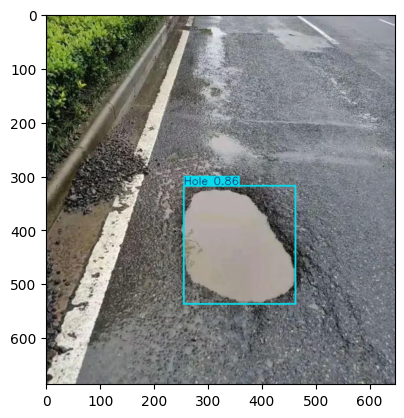

In [40]:
import matplotlib.pyplot as plt

plt.imshow(results[0].plot()[..., ::-1]);

In [41]:
from ultralytics import YOLO

model = YOLO(r"/content/runs/detect/train-3/weights/best.pt")


metrics = model.val(
    data=r"/content/damage-detection-5/data.yaml",
    split="val",
    plots=True
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1455.8±386.4 MB/s, size: 102.4 KB)
val: Scanning /content/damage-detection-5/valid/labels.cache... 94 images, 1 backgrounds, 2 corrupt: 100% ━━━━━━━━━━━━ 94/94 16.4Mit/s 0.0s
val: /content/damage-detection-5/valid/images/301_jpg.rf.002e1e037a853c240ebc538ae4f167bb.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/damage-detection-5/valid/images/316_jpg.rf.7b2b117a8aacbe8c654db59bff9fe516.jpg: ignoring corrupt image/label: labels mix segment and detection rows
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 93, len(boxes) = 190. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
          

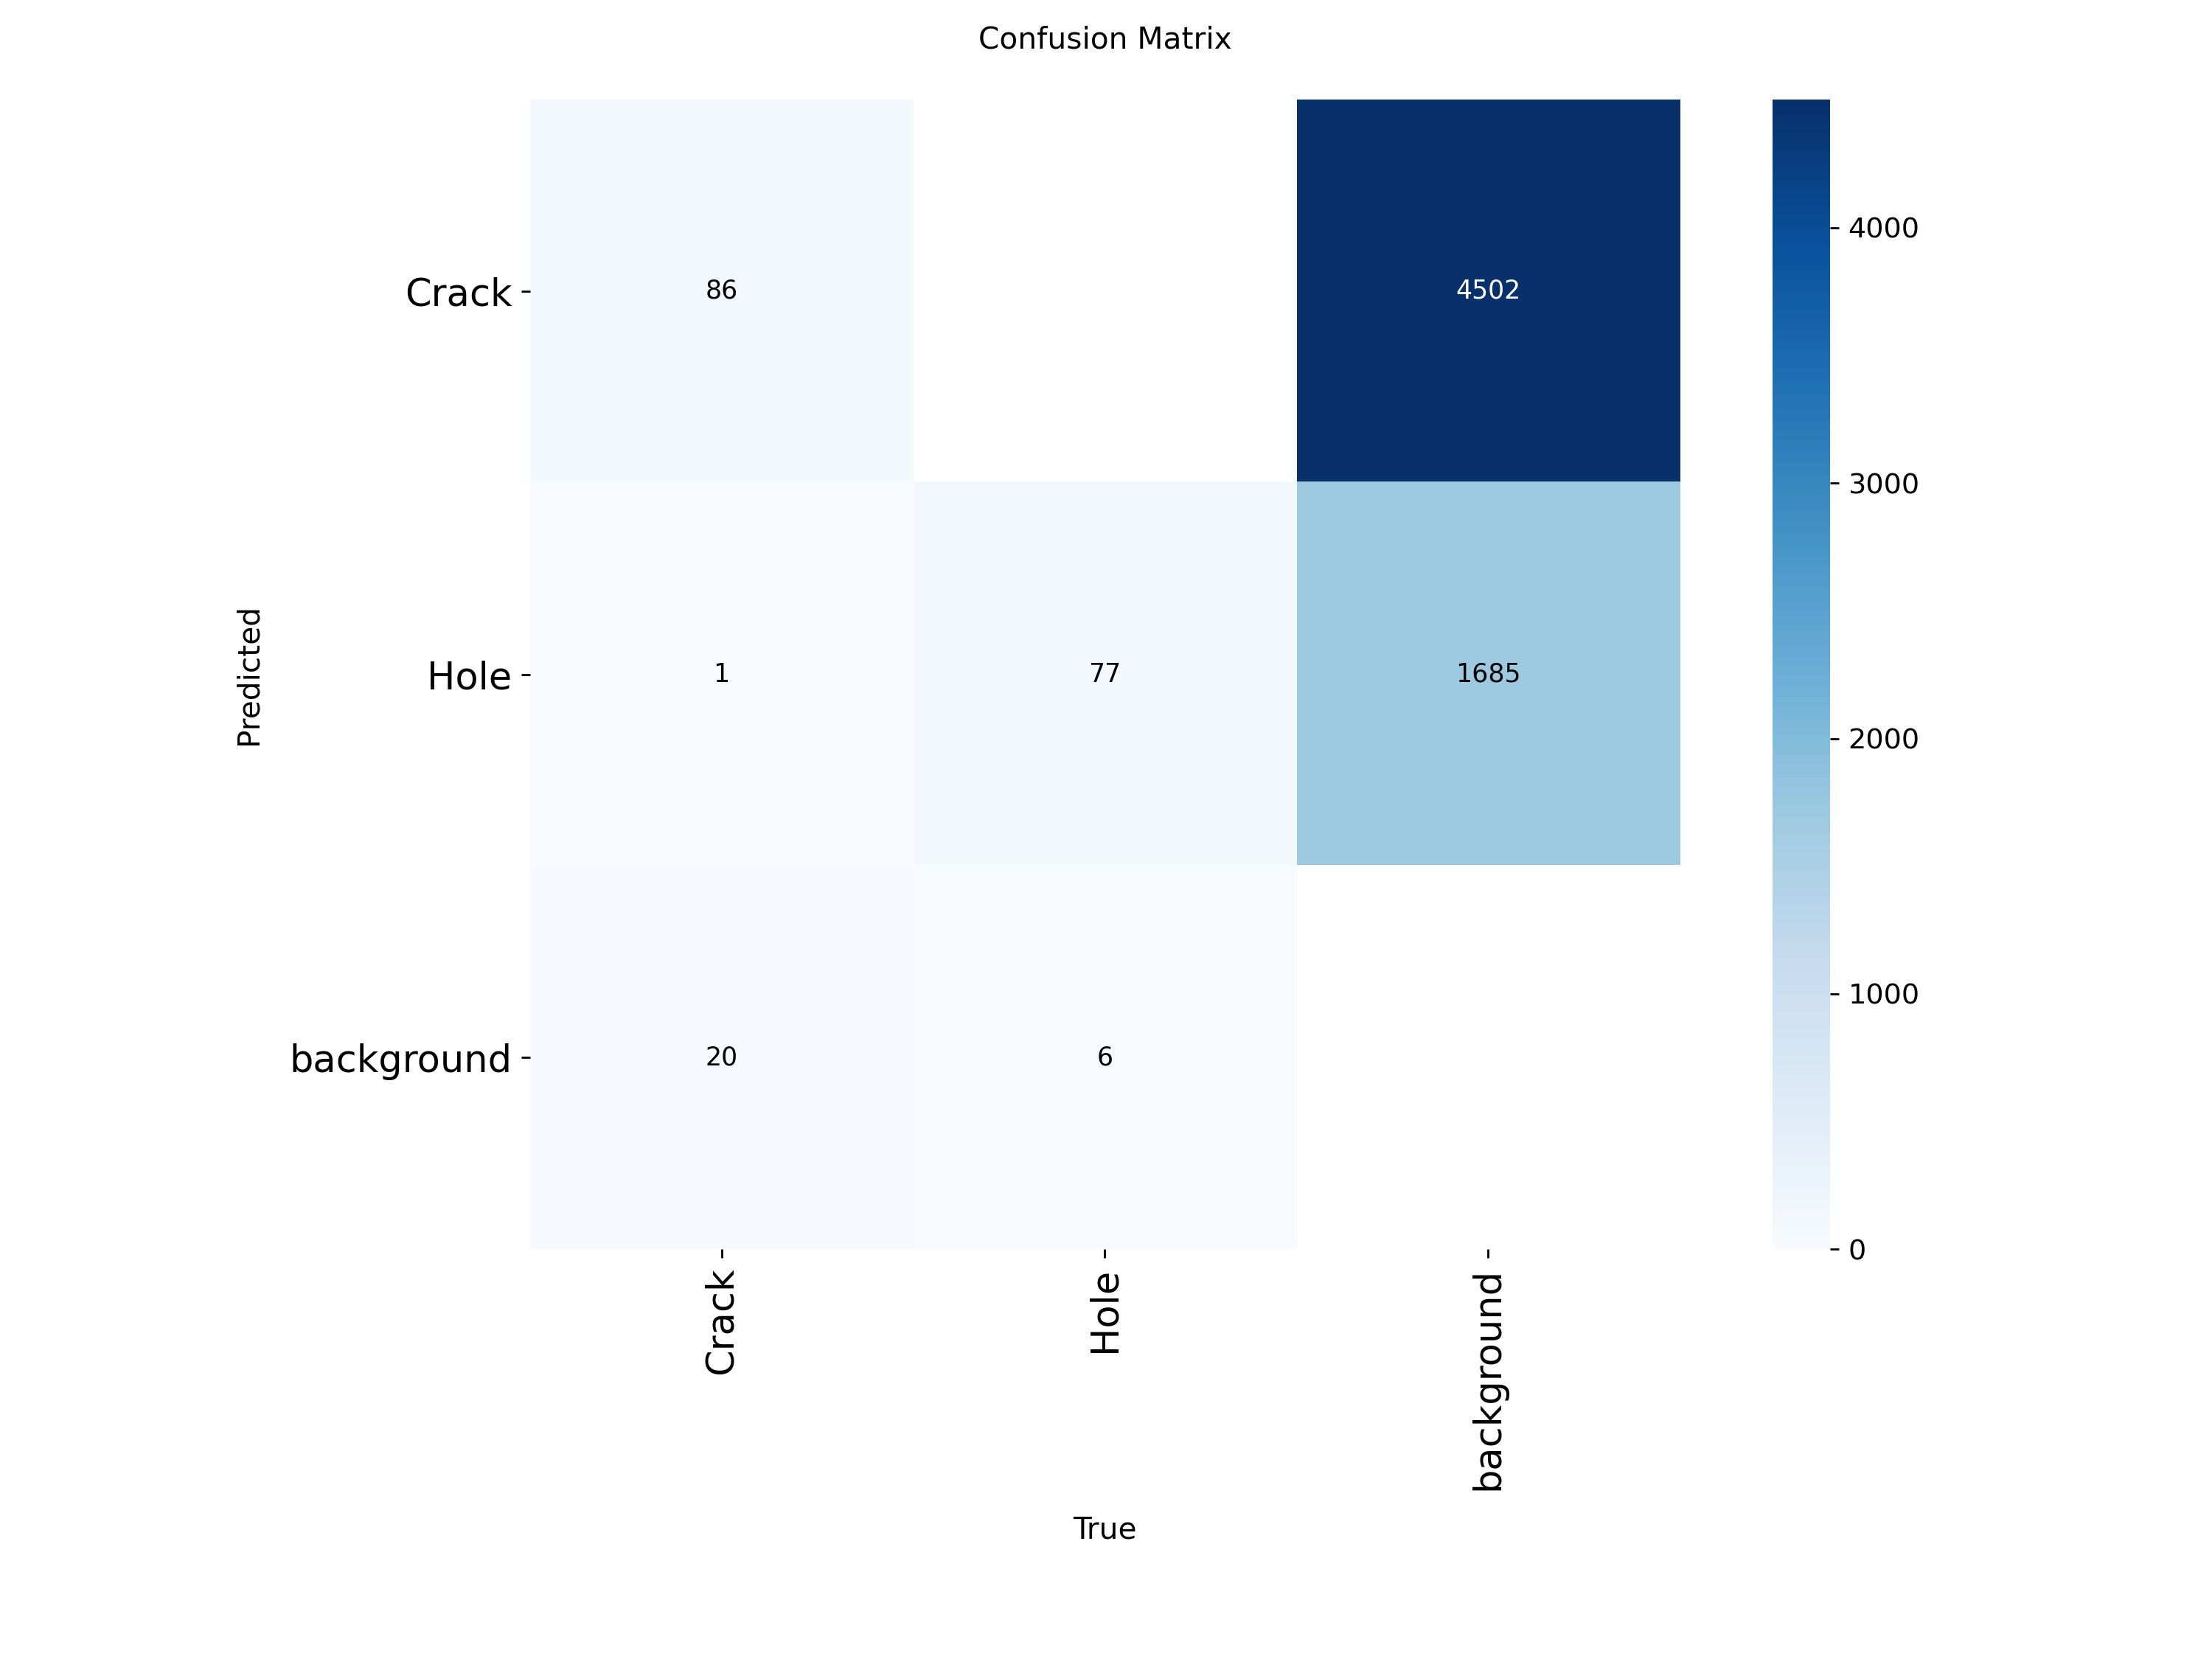

In [42]:
from IPython.display import Image, display

display(Image(
    filename=str(metrics.save_dir / "confusion_matrix.png"),
    width=500
))
